In [45]:
import polars as pl
from datetime import date, timedelta
import yaml
import json
import matplotlib.pyplot as plt
import dayplot as dp
from pathlib import Path


def daterange(start_date: date, end_date: date):
    days = (end_date - start_date).days
    for n in range(days + 1):
        yield start_date + timedelta(n)


with open("../config.yaml", "r") as fp:
    config = yaml.safe_load(fp)

In [2]:
data = pl.read_csv(
    config["dirs"]["pickwell"] + "/2023/10/01/location-82840-part0000.csv.gz",
    separator="\t",
    schema_overrides={"altitude_accuracy": pl.Float64, "OS_version": pl.String},
)

In [47]:
def determine_descriptives(d: date) -> dict[str, int]:
    result = {}
    path = Path(f"{config['dirs']['pickwell']}/{d.strftime('%Y/%m/%d')}")
    data = pl.DataFrame()
    for i in sorted(path.glob("*.csv.gz")):
        part = pl.read_csv(
            i,
            separator="\t",
            quote_char=None,
            schema_overrides={"altitude_accuracy": pl.Float64, "OS_version": pl.String},
        )
        data = pl.concat([data, part])
    result["number_of_records"] = len(data)
    result["number_of_unique_devices"] = len(data["device_aid_hashed"].unique())
    return result

In [37]:
try:
    with open("../output/descriptives/counts_2023.json", "r") as fp:
        counts_2023 = json.load(fp)
except FileNotFoundError:
    # runs 3 minutes for 2023-10-01--2023-12-31
    counts_2023 = {}
    for i in daterange(date(2023, 10, 1), date(2023, 12, 31)):
        counts_2023[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    with open("../output/descriptives/counts_2023.json", "w") as fp:
        json.dump(counts_2023, fp, indent=1)


In [38]:
try:
    with open("../output/descriptives/counts_2024.json", "r") as fp:
        counts_2024 = json.load(fp)
except FileNotFoundError:
    # runs 5 minutes
    counts_2024 = {}
    for i in daterange(date(2024, 1, 1), date(2024, 2, 29)):
        counts_2024[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    for i in daterange(date(2024, 10, 1), date(2024, 12, 31)):
        counts_2024[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    with open("../output/descriptives/counts_2024.json", "w") as fp:
        json.dump(counts_2024, fp, indent=1)


In [39]:
try:
    with open("../output/descriptives/counts_2025.json", "r") as fp:
        counts_2025 = json.load(fp)
except FileNotFoundError:
    # runs 15 minutes
    counts_2025 = {}
    for i in daterange(date(2025, 1, 1), date(2025, 12, 31)):
        counts_2025[i.strftime("%Y-%m-%d")] = determine_descriptives(i)
    with open("../output/descriptives/counts_2025.json", "w") as fp:
        json.dump(counts_2025, fp, indent=1)

In [31]:
def counts_to_dataframe(counts: dict[str, dict[str, int]]) -> pl.DataFrame:
    records = []
    for k, v in counts.items():
        records.append(
            [
                date(*map(int, k.split("-"))),
                v["number_of_records"],
                v["number_of_unique_devices"],
            ]
        )
    return pl.from_records(
        records,
        schema=["day", "number_of_records", "number_of_unique_devices"],
        orient="row",
    )

In [40]:
cdf_23 = counts_to_dataframe(counts_2023)
cdf_24 = counts_to_dataframe(counts_2024)
cdf_25 = counts_to_dataframe(counts_2025)

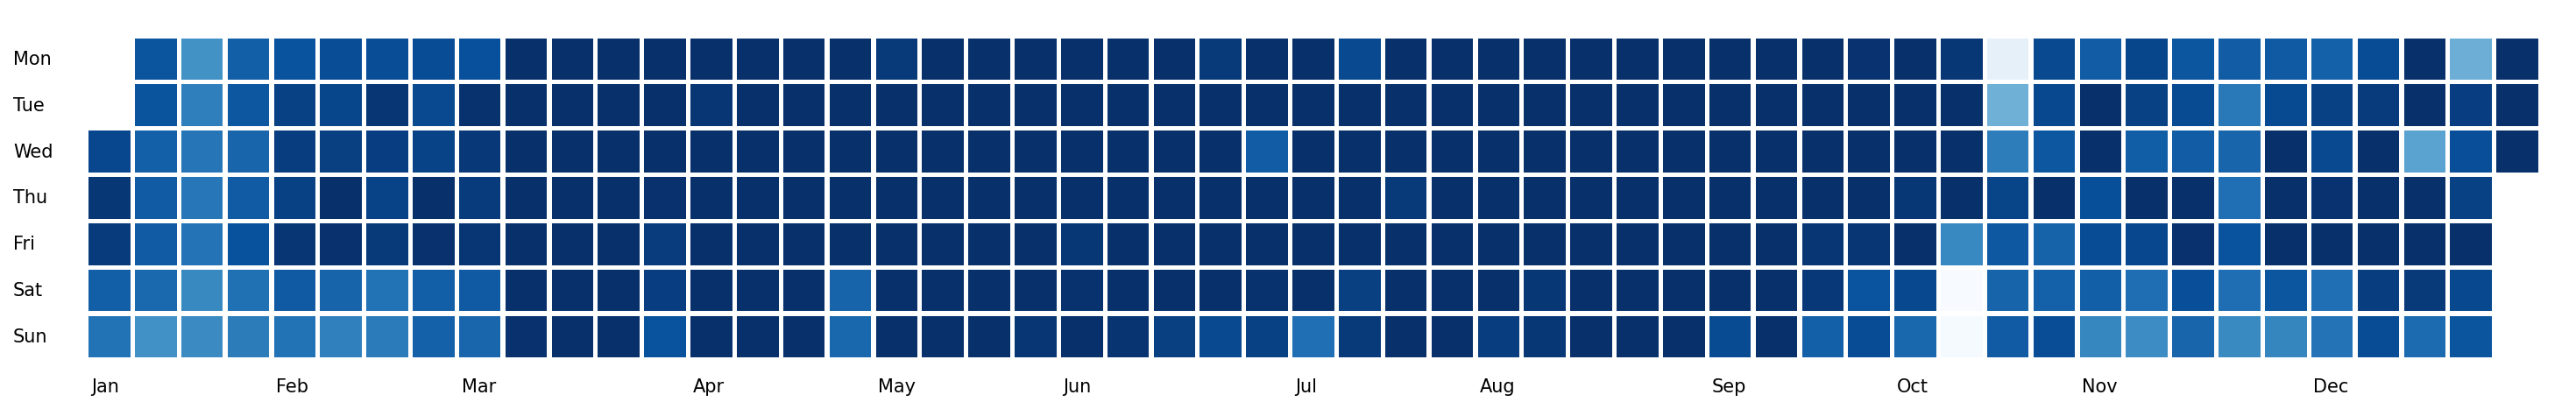

In [41]:
fig, ax = plt.subplots(figsize=(30, 3), dpi=150, layout="constrained")
_ = dp.calendar(
    dates=cdf_25["day"],
    values=cdf_25["number_of_records"],
    start_date="2025-01-01",
    end_date="2025-12-31",
    week_starts_on="Monday",
    ax=ax,
    cmap="Blues",
)


# for i in ["png", "svg"]:
#     fig.savefig(
#         f"../output/descriptives/number_of_records.{i}",
#         metadata=config["metadata"][i],
#     )